<a href="https://colab.research.google.com/github/SitiMutmainah15/PEMBELAJARAN-MESIN_GENAP_2026/blob/main/JS07/TUGAS07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SOAL 1

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score
from google.colab import files

df = pd.read_csv('CC_Customer_Dataset.csv')
print('Jumlah data:', len(df))
df.head()

Jumlah data: 660


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


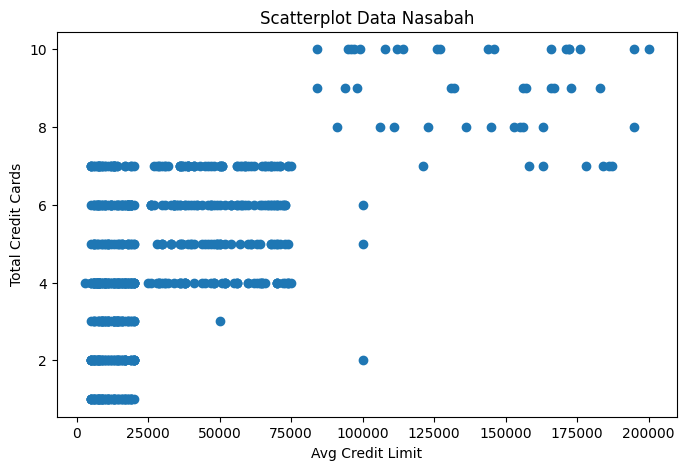

Korelasi: 0.609


In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'])
plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')
plt.title('Scatterplot Data Nasabah')
plt.show()

print('Korelasi:', round(df['Avg_Credit_Limit'].corr(df['Total_Credit_Cards']), 3))

Limit kredit yang lebih tinggi cenderung diikuti jumlah kartu yang lebih banyak. Korelasinya 0,609 (positif), tetapi titik2 tidak membentuk garis lurus yang rapat, sehingga sebarannya tidak sepenuhnya linier.

SOAL 2

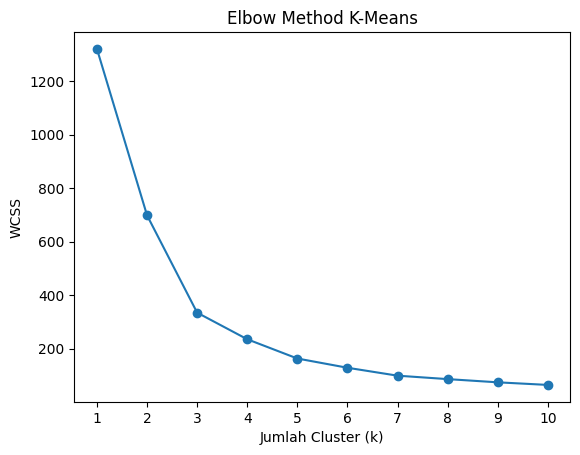

Cluster_KMeans
0    330
1     48
2    282
Name: count, dtype: int64


In [6]:
kolom = ['Avg_Credit_Limit', 'Total_Credit_Cards']
X = StandardScaler().fit_transform(df[kolom])

wcss = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('WCSS')
plt.title('Elbow Method K-Means')
plt.xticks(range(1, 11))
plt.show()

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster_KMeans'] = kmeans.fit_predict(X)
print(df['Cluster_KMeans'].value_counts().sort_index())

Titik siku berada sekitar k = 3, karena setelah itu grafik WCSS mulai lebih landai. Karena itu saya memilih 3 kelompok nasabah. Data distandardisasi supaya limit kredit yang besar tidak mendominasi perhitungan jarak.

SOAL 3

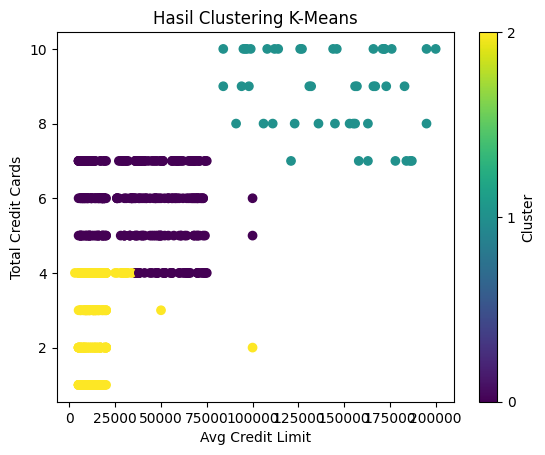

                Avg_Credit_Limit  Total_Credit_Cards
Cluster_KMeans                                      
0                        37161.0                 6.0
1                       142750.0                 9.0
2                        13135.0                 3.0


In [7]:
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'],
            c=df['Cluster_KMeans'], cmap='viridis')
plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')
plt.title('Hasil Clustering K-Means')
plt.colorbar(label='Cluster', ticks=[0, 1, 2])
plt.show()

print(df.groupby('Cluster_KMeans')[kolom].mean().round(0))

K-Means membentuk tiga kelompok berdasarkan rata-rata limit dan jumlah kartu kredit. Kelompok dengan karakteristik rendah, sedang, dan tinggi bisa dilihat dari tabel rata-ratanya. Nomor label klaster hanya penanda, bukan urutan kualitas.

SOAL 4

In [8]:
fitur = ['Avg_Credit_Limit', 'Total_Credit_Cards',
         'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
X_db = StandardScaler().fit_transform(df[fitur])

dbscan = DBSCAN(eps=1.2, min_samples=10)
df['Cluster_DBSCAN'] = dbscan.fit_predict(X_db)
print(df['Cluster_DBSCAN'].value_counts().sort_index())

Cluster_DBSCAN
-1     13
 0    608
 1     39
Name: count, dtype: int64


Saya menggunakan 5 variabel karakteristik nasabah. Sl_No dan Customer Key tidak digunakan karena hanya penanda identitas. Dengan parameter tersebut, DBSCAN membentuk 2 klaster (608 dan 39 nasabah), sementara 13 data termasuk noise (-1).

SOAL 5

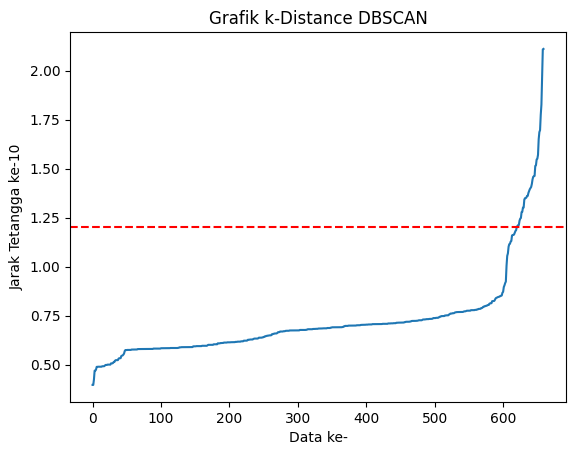

In [9]:
jarak, _ = NearestNeighbors(n_neighbors=10).fit(X_db).kneighbors(X_db)
jarak_urut = np.sort(jarak[:, -1])

plt.plot(jarak_urut)
plt.axhline(y=1.2, color='red', linestyle='--')
plt.xlabel('Data ke-')
plt.ylabel('Jarak Tetangga ke-10')
plt.title('Grafik k-Distance DBSCAN')
plt.show()

DBSCAN tidak menggunakan jumlah klaster k seperti K-Means. Oleh karena itu, saya menggunakan grafik k-distance untuk membantu menentukan nilai eps. Berdasarkan grafik tersebut, saya mencoba eps sebesar 1.2 dengan min_samples = 10. Hasilnya terbentuk 2 klaster dan 13 data noise.

SOAL 6

In [10]:
mask = df['Cluster_DBSCAN'] != -1  # noise tidak dihitung
sil = silhouette_score(X_db[mask], df.loc[mask, 'Cluster_DBSCAN'])
dbi = davies_bouldin_score(X_db[mask], df.loc[mask, 'Cluster_DBSCAN'])

print('Silhouette Score:', round(sil, 3))
print('Davies-Bouldin Index:', round(dbi, 3))

Silhouette Score: 0.569
Davies-Bouldin Index: 0.607


Silhouette Score = 0,569 dan DBI = 0,607 setelah mengecualikan 13 noise. Nilai silhouette positif menunjukkan klaster cukup terpisah. Semakin rendah DBI, semakin baik. Hasil ini menunjukkan pengelompokan yang cukup baik untuk parameter yang dipakai.

KESIMPULAN:
K-Means membagi 660 nasabah menjadi 3 klaster dari dua variabel, sedangkan DBSCAN dengan lima variabel membentuk 2 klaster dan 13 noise. Hasil kedua metode berbeda karena cara pengelompokannya berbeda. Semua grafik ditampilkan langsung di Colab tanpa disimpan sebagai file.